# Transportation Models and Their Variants

Transportation optimization, production–inventory allocation, assignment, and transshipment are modeled as linear programs. Each example presents its decision context, numerical formulation, algorithm calculations, solver solution, and operational interpretation. Costs and datasets in the named examples are drawn from *Operations Research: An Introduction*, 8th ed., Chapter 5.

**Notation:** $x_{ij}$ is the nonnegative quantity assigned from origin $i$ to destination $j$, $c_{ij}$ is cost per unit, $a_i$ is available supply, and $b_j$ is required demand. Shipment quantities are continuous in LP; where truckload/car counts are treated as indivisible, integer feasibility should be confirmed (transportation models with integral balanced margins admit integral extreme-point optima).

## Setup

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog, linear_sum_assignment
from IPython.display import display
np.set_printoptions(precision=3, suppress=True)
pd.set_option('display.precision', 3)


## 1. Automobile Distribution: Balanced Transportation Model

**Problem.** MG Auto ships cars from three assembly plants (Los Angeles, Detroit, New Orleans) to distribution centers (Denver, Miami). Daily plant supplies are 1,000, 1,500, and 1,200 cars; destination requirements are 2,300 and 1,400 cars. Transportation cost depends on the origin–destination pair. The objective is to meet every destination's demand with the minimum total freight cost.

| Origin | Denver ($/car) | Miami ($/car) | Supply (cars) |/
|---|---:|---:|---:|
| Los Angeles | 80 | 215 | 1,000 |
| Detroit | 100 | 108 | 1,500 |
| New Orleans | 102 | 68 | 1,200 |
| **Demand** | **2,300** | **1,400** | **3,700** |

**Decision variables.** Let $x_{ij}$ represent the number of cars shipped from plant $i$ to destination $j$, where $i=1,2,3$ and $j=1,2$.

**Objective and all constraints**

$$
\min z = 80x_{11}+215x_{12}+100x_{21}+108x_{22}+102x_{31}+68x_{32}
$$

Subject to:

**Supply constraints**

$$
\begin{aligned}
x_{11}+x_{12} &= 1000 && \text{(Los Angeles)}\\
x_{21}+x_{22} &= 1500 && \text{(Detroit)}\\
x_{31}+x_{32} &= 1200 && \text{(New Orleans)}
\end{aligned}
$$

**Demand constraints**

$$
\begin{aligned}
x_{11}+x_{21}+x_{31} &= 2300 && \text{(Denver)}\\
x_{12}+x_{22}+x_{32} &= 1400 && \text{(Miami)}
\end{aligned}
$$

**Nonnegativity constraints**

$$
x_{ij}\geq 0,\qquad i=1,2,3;\quad j=1,2
$$

Total supply:

$$
1000+1500+1200=3700
$$

Total demand:

$$
2300+1400=3700
$$

Because total supply equals total demand (3,700 cars), this is a **balanced transportation model**, and no dummy location is required.


In [25]:
def transportation_lp(cost, supply, demand):
    cost=np.asarray(cost,dtype=float); supply=np.asarray(supply,dtype=float); demand=np.asarray(demand,dtype=float)
    m,k=cost.shape
    assert len(supply)==m and len(demand)==k
    assert abs(supply.sum()-demand.sum())<1e-7, 'Model must first be balanced'
    E=[]; b=[]
    for i in range(m):
        row=np.zeros((m,k));row[i,:]=1;E.append(row.ravel());b.append(supply[i])
    for j in range(k):
        row=np.zeros((m,k));row[:,j]=1;E.append(row.ravel());b.append(demand[j])
    res=linprog(cost.ravel(),A_eq=np.array(E),b_eq=np.array(b),bounds=(0,None),method='highs')
    if not res.success: raise RuntimeError(res.message)
    return res.x.reshape(m,k),float(res.fun),res
mg_c=np.array([[80,215],[100,108],[102,68]])
mg_s=np.array([1000,1500,1200]);mg_d=np.array([2300,1400])
mg_x,mg_z,mg_result=transportation_lp(mg_c,mg_s,mg_d)
display(pd.DataFrame(mg_x,index=['Los Angeles','Detroit','New Orleans'],columns=['Denver','Miami']))
print(f'Minimum transportation cost: ${mg_z:,.0f}')
assert abs(mg_z-313200)<1e-6

,Denver,Miami
Los Angeles,1000.0,0.0
Detroit,1300.0,200.0
New Orleans,0.0,1200.0


Minimum transportation cost: $313,200


**Interpretation.** Send 1,000 cars from Los Angeles to Denver; 1,300 from Detroit to Denver and 200 from Detroit to Miami; and 1,200 from New Orleans to Miami. These shipments satisfy all five balances at a total cost of **$313,200**. The decision does not mean the lowest-rate route is used exclusively: limited origin capacity and destination requirements jointly determine the plan.

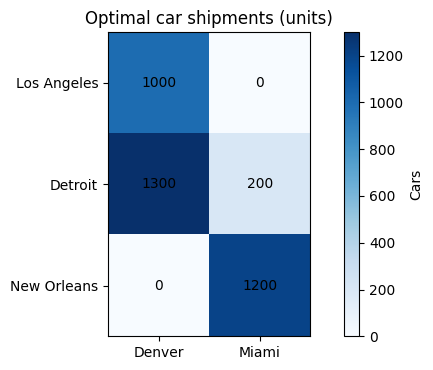

In [26]:
fig,ax=plt.subplots(figsize=(7,3.8));im=ax.imshow(mg_x,cmap='Blues');ax.set_xticks(range(2),['Denver','Miami']);ax.set_yticks(range(3),['Los Angeles','Detroit','New Orleans'])
for i in range(3):
 for j in range(2): ax.text(j,i,f'{mg_x[i,j]:.0f}',ha='center',va='center',color='black')
ax.set_title('Optimal car shipments (units)');fig.colorbar(im,ax=ax,label='Cars');plt.tight_layout();plt.show()

### Unbalanced models and dummy locations

**Problem modification.** If Detroit supplies only 1,300 cars, total supply is 3,500 but demand remains 3,700; therefore 200 cars of demand cannot be served. Add a **dummy source** of 200 cars. Dummy shipments represent shortages rather than physical movements. With zero dummy costs, the algorithm minimizes physical freight without penalizing shortage location.

$$
\text{Dummy supply}=3700-3500=200.
$$

If instead supply exceeds demand, add a dummy **destination** for surplus capacity. Penalty costs can express different shortage priorities or disposal costs.

In [27]:
short_c=np.vstack([mg_c,np.zeros(2)])
short_x,short_z,_=transportation_lp(short_c,[1000,1300,1200,200],mg_d)
display(pd.DataFrame(short_x,index=['Los Angeles','Detroit','New Orleans','Dummy shortage'],columns=['Denver','Miami']))
print('Physical freight cost:',short_z,'; unmet demand (cars):',short_x[-1].sum())

,Denver,Miami
Los Angeles,1000.0,0.0
Detroit,1300.0,0.0
New Orleans,0.0,1200.0
Dummy shortage,-0.0,200.0


Physical freight cost: 291600.0 ; unmet demand (cars): 200.0


## 2. Production–inventory planning as a transportation model

**Problem.** Boralis makes backpacks during March–June with monthly capacities of 50, 180, 280, and 270. Monthly demands are 100, 200, 180, and 300. Each backpack costs $40 to produce. Inventory held for a later month costs $0.50 per unit per month; backorders completed after their demand month cost $2 per unit per month. Determine which production month satisfies each demand month at minimum total cost.

Let $x_{ij}$ = units produced in month $i$ to satisfy demand in month $j$, with $i,j\in\{1,2,3,4\}$. The four source capacities sum to 780, exactly matching total demand.

$$

 c_{ij}=\begin{cases}40+0.50(j-i),&i<j\\40,&i=j\\40+2(i-j),&i>j.\end{cases}

$$

In particular, $c_{24}=40+0.5(4-2)=41$ and $c_{41}=40+2(4-1)=46$.

**Objective (all numerical terms):**

$$

\begin{aligned}
\min z={}&40x_{11}+40.5x_{12}+41x_{13}+41.5x_{14}\\
&+42x_{21}+40x_{22}+40.5x_{23}+41x_{24}\\
&+44x_{31}+42x_{32}+40x_{33}+40.5x_{34}\\
&+46x_{41}+44x_{42}+42x_{43}+40x_{44}.
\end{aligned}

$$

**Numerical supply constraints:**

$$

\begin{aligned}
x_{11}+x_{12}+x_{13}+x_{14}&=50\\
x_{21}+x_{22}+x_{23}+x_{24}&=180\\
x_{31}+x_{32}+x_{33}+x_{34}&=280\\
x_{41}+x_{42}+x_{43}+x_{44}&=270.
\end{aligned}

$$

**Numerical demand constraints:**

$$

\begin{aligned}
x_{11}+x_{21}+x_{31}+x_{41}&=100\\
x_{12}+x_{22}+x_{32}+x_{42}&=200\\
x_{13}+x_{23}+x_{33}+x_{43}&=180\\
x_{14}+x_{24}+x_{34}+x_{44}&=300.
\end{aligned}

$$

All $x_{ij}\ge0$. A cell with $i<j$ represents inventory, $i>j$ represents backordering, and $i=j$ represents immediate fulfillment.

In [28]:
months=['Mar','Apr','May','Jun'];bs=np.array([50,180,280,270]);bd=np.array([100,200,180,300]);bc=np.array([[40+(j-i)*.5 if j>=i else 40+(i-j)*2 for j in range(4)] for i in range(4)])
production,prod_cost,_=transportation_lp(bc,bs,bd)
display(pd.DataFrame(bc,index=months,columns=months));display(pd.DataFrame(production,index=months,columns=months));print('Optimal total cost:',prod_cost)
assert abs(prod_cost-31455)<1e-6
print('Immediate:',np.trace(production),'carried:',np.triu(production,1).sum(),'backordered:',np.tril(production,-1).sum())

,Mar,Apr,May,Jun
Mar,40.0,40.5,41.0,41.5
Apr,42.0,40.0,40.5,41.0
May,44.0,42.0,40.0,40.5
Jun,46.0,44.0,42.0,40.0


,Mar,Apr,May,Jun
Mar,50.0,0.0,0.0,0.0
Apr,0.0,180.0,0.0,0.0
May,50.0,20.0,180.0,30.0
Jun,0.0,0.0,0.0,270.0


Optimal total cost: 31455.0
Immediate: 680.0 carried: 30.0 backordered: 70.0


**Interpretation.** The total expense is **$31,455**. The allocation matrix identifies exactly which monthly orders are supplied on time, early through inventory, or late through backordering. The $31,200 base production charge is unavoidable for 780 backpacks; the difference represents inventory and backorder costs.

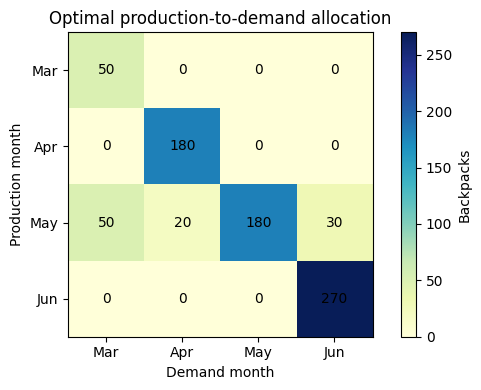

In [29]:
fig,ax=plt.subplots(figsize=(6,4));im=ax.imshow(production,cmap='YlGnBu');ax.set_xticks(range(4),months);ax.set_yticks(range(4),months);ax.set_xlabel('Demand month');ax.set_ylabel('Production month');ax.set_title('Optimal production-to-demand allocation');
for i in range(4):
 for j in range(4): ax.text(j,i,str(int(production[i,j])),ha='center',va='center')
fig.colorbar(im,ax=ax,label='Backpacks');plt.tight_layout();plt.show()

## 3. Transportation algorithms: SunRay grain shipments

**Problem.** Three grain silos supply 15, 25, and 10 truckloads to four mills requiring 5, 15, 15, and 15 truckloads. Costs (hundreds of dollars per truckload) are below. Determine a feasible shipping plan and improve it until total transportation cost is minimized.

| Silo | Mill 1 | Mill 2 | Mill 3 | Mill 4 | Supply |
|---|---:|---:|---:|---:|---:|
| 1 | 10 | 2 | 20 | 11 | 15 |
| 2 | 12 | 7 | 9 | 20 | 25 |
| 3 | 4 | 14 | 16 | 18 | 10 |
| **Demand** | **5** | **15** | **15** | **15** | **50** |

For $x_{ij}$ = truckloads transported from silo $i$ to mill $j$:

$$

\begin{aligned}
\min z={}&10x_{11}+2x_{12}+20x_{13}+11x_{14}\\
&+12x_{21}+7x_{22}+9x_{23}+20x_{24}\\
&+4x_{31}+14x_{32}+16x_{33}+18x_{34}.
\end{aligned}

$$

Source and destination constraints, written numerically, are:

$$

\begin{aligned}
x_{11}+x_{12}+x_{13}+x_{14}&=15\\
x_{21}+x_{22}+x_{23}+x_{24}&=25\\
x_{31}+x_{32}+x_{33}+x_{34}&=10\\
x_{11}+x_{21}+x_{31}&=5\\
x_{12}+x_{22}+x_{32}&=15\\
x_{13}+x_{23}+x_{33}&=15\\
x_{14}+x_{24}+x_{34}&=15,
\end{aligned}

$$

with $x_{ij}\ge0$. All monetary values reported from this cost matrix are in **hundreds of dollars**.

### Northwest Corner: how the algorithm works

**Purpose.** Construct a feasible starting allocation without examining shipping costs. This is a *feasibility method*, not an optimality method.

At iteration $k$, let $a_i^{(k)}$ be unallocated supply in the active row and $b_j^{(k)}$ be unmet demand in the active column.

$$
q_k=\min\!\left(a_i^{(k)},b_j^{(k)}\right),\qquad
x_{ij}\leftarrow x_{ij}+q_k.
$$

After allocating $q_k$, subtract it from both the active supply and demand. When a row is exhausted, move **down**; when a column is fulfilled, move **right**. If both become zero together, one zero-valued basic cell may be needed to maintain $m+n-1$ basis cells for later MODI iterations. Stop after every supply and demand is met. The first demonstration below prints **every decision and the resulting allocation matrix**.

### 3.1 Northwest Corner initialization

The algorithm begins at cell $(1,1)$ without considering costs. At each step, allocate $\min(\text{remaining row supply},\text{remaining column demand})$; delete an exhausted row or column and move right or down.

The allocations are:

$$
x_{11}=5,\quad x_{12}=10,\quad x_{22}=5,\quad x_{23}=15,\quad x_{24}=5,\quad x_{34}=10.
$$
$$
z=5(10)+10(2)+5(7)+15(9)+5(20)+10(18)=520.
$$

The initial freight expense is $520\times100=\$52,000$. The number of basic cells required for a nondegenerate transportation basis is $m+n-1=3+4-1=6$.

In [30]:
sc=np.array([[10,2,20,11],[12,7,9,20],[4,14,16,18]],float); ss=np.array([15,25,10]);dd=np.array([5,15,15,15])
def northwest(s,d):
 s=s.astype(float).copy();d=d.astype(float).copy();x=np.zeros((len(s),len(d)));steps=[];i=j=0
 while i<len(s) and j<len(d):
  v=min(s[i],d[j]);x[i,j]=v;steps.append((i+1,j+1,v));s[i]-=v;d[j]-=v
  if abs(s[i])<1e-9:i+=1
  elif abs(d[j])<1e-9:j+=1
 return x,steps
nw,nw_steps=northwest(ss,dd)
print('NW steps (row,column,units):',nw_steps);display(pd.DataFrame(nw,index=['S1','S2','S3'],columns=['M1','M2','M3','M4']));print('Cost (hundreds):',np.sum(nw*sc))

NW steps (row,column,units): [(1, 1, np.float64(5.0)), (1, 2, np.float64(10.0)), (2, 2, np.float64(5.0)), (2, 3, np.float64(15.0)), (2, 4, np.float64(5.0)), (3, 4, np.float64(10.0))]


,M1,M2,M3,M4
S1,5.0,10.0,0.0,0.0
S2,0.0,5.0,15.0,5.0
S3,0.0,0.0,0.0,10.0


Cost (hundreds): 520.0


### Complete Northwest Corner iteration history

The following implementation records the selected cell, supply and demand before allocation, allocated amount, the updated residuals, and the cumulative cost after every iteration. At the end, the row and column totals must reproduce the original supply and demand.

In [31]:
def print_transport_trace(trace, cost, shape):
    for t in trace:
        print(f"Step {t['step']}: cell ({t['i']+1},{t['j']+1}), "
              f"supply={t['s_before']:g}, demand={t['d_before']:g}, "
              f"allocate={t['quantity']:g}, cumulative cost={t['cost']:g}")
        display(pd.DataFrame(t['allocation'], index=[f'Silo {r+1}' for r in range(shape[0])],
                             columns=[f'Mill {j+1}' for j in range(shape[1])]))
        print('Remaining supply:',t['supply'],'Remaining demand:',t['demand'])

def northwest_trace(cost, supply, demand):
    cost=np.asarray(cost,float); s=np.array(supply,float).copy(); d=np.array(demand,float).copy()
    x=np.zeros_like(cost); basis=[]; trace=[]; i=j=k=0
    while i<len(s) and j<len(d):
        k+=1; sb,db=s[i],d[j]; q=min(sb,db)
        x[i,j]+=q; basis.append((i,j)); s[i]-=q; d[j]-=q
        trace.append(dict(step=k,i=i,j=j,s_before=sb,d_before=db,quantity=q,
                          cost=float((x*cost).sum()),allocation=x.copy(),
                          supply=s.copy(), demand=d.copy()))
        if abs(s[i])<1e-9 and abs(d[j])<1e-9: i+=1;j+=1
        elif abs(s[i])<1e-9: i+=1
        else: j+=1
    return x,basis,trace
nw_x,nw_basis,nw_history=northwest_trace(sc,ss,dd)
print_transport_trace(nw_history,sc,sc.shape)
assert np.allclose(nw_x.sum(axis=1),ss) and np.allclose(nw_x.sum(axis=0),dd)
assert abs((nw_x*sc).sum()-520)<1e-8

Step 1: cell (1,1), supply=15, demand=5, allocate=5, cumulative cost=50


,Mill 1,Mill 2,Mill 3,Mill 4
Silo 1,5.0,0.0,0.0,0.0
Silo 2,0.0,0.0,0.0,0.0
Silo 3,0.0,0.0,0.0,0.0


Remaining supply: [10. 25. 10.] Remaining demand: [ 0. 15. 15. 15.]
Step 2: cell (1,2), supply=10, demand=15, allocate=10, cumulative cost=70


,Mill 1,Mill 2,Mill 3,Mill 4
Silo 1,5.0,10.0,0.0,0.0
Silo 2,0.0,0.0,0.0,0.0
Silo 3,0.0,0.0,0.0,0.0


Remaining supply: [ 0. 25. 10.] Remaining demand: [ 0.  5. 15. 15.]
Step 3: cell (2,2), supply=25, demand=5, allocate=5, cumulative cost=105


...

Remaining supply: [ 0.  5. 10.] Remaining demand: [ 0.  0.  0. 15.]
Step 5: cell (2,4), supply=5, demand=15, allocate=5, cumulative cost=340


,Mill 1,Mill 2,Mill 3,Mill 4
Silo 1,5.0,10.0,0.0,0.0
Silo 2,0.0,5.0,15.0,5.0
Silo 3,0.0,0.0,0.0,0.0


Remaining supply: [ 0.  0. 10.] Remaining demand: [ 0.  0.  0. 10.]
Step 6: cell (3,4), supply=10, demand=10, allocate=10, cumulative cost=520


,Mill 1,Mill 2,Mill 3,Mill 4
Silo 1,5.0,10.0,0.0,0.0
Silo 2,0.0,5.0,15.0,5.0
Silo 3,0.0,0.0,0.0,10.0


Remaining supply: [0. 0. 0.] Remaining demand: [0. 0. 0. 0.]


### 3.2 Least Cost initialization

Select the remaining cell with the smallest unit cost, allocate as much as possible, update balances, and repeat. This uses cost information, but it does not guarantee a global optimum. The code below prints every assignment. Ties are broken by row/column order.

### Least Cost: how the algorithm works

**Purpose.** Obtain a feasible plan that uses inexpensive routes early. Unlike Northwest Corner, this method considers freight costs but **does not guarantee optimality**.

At each iteration, find the smallest $c_{ij}$ among currently usable rows and columns; allocate

$$
q_k=\min\!\left(a_i^{(k)},b_j^{(k)}\right).
$$

Update the supply and demand, deactivate exhausted rows/columns, and repeat. For ties, this implementation chooses the available cell with the largest possible allocation, then row/column order. The tie rule affects the starting solution. The algorithm ends when all demand has been satisfied. Each decision and remaining balance are shown below.

In [32]:
def least_cost(cost,s,d):
 s=s.astype(float).copy();d=d.astype(float).copy();x=np.zeros_like(cost,dtype=float);trace=[]
 while np.any(s>1e-9):
  candidates=[(cost[i,j],i,j) for i in range(len(s)) for j in range(len(d)) if s[i]>1e-9 and d[j]>1e-9]
  _,i,j=min(candidates);q=min(s[i],d[j]);x[i,j]+=q;s[i]-=q;d[j]-=q;trace.append((i+1,j+1,q))
 return x,trace
lc,lc_steps=least_cost(sc,ss,dd)
print('Least-cost allocations:',lc_steps);display(pd.DataFrame(lc));print('Cost (hundreds):',np.sum(lc*sc))

Least-cost allocations: [(1, 2, np.float64(15.0)), (3, 1, np.float64(5.0)), (2, 3, np.float64(15.0)), (3, 4, np.float64(5.0)), (2, 4, np.float64(10.0))]


,0,1,2,3
0,0.0,15.0,0.0,0.0
1,0.0,0.0,15.0,10.0
2,5.0,0.0,0.0,5.0


Cost (hundreds): 475.0


In [33]:
def least_cost_trace(cost,supply,demand):
    cost=np.asarray(cost,float);s=np.asarray(supply,float).copy();d=np.asarray(demand,float).copy()
    x=np.zeros_like(cost);trace=[];step=0
    while s.sum()>1e-9:
        cells=[(cost[i,j],-min(s[i],d[j]),i,j) for i in range(len(s)) for j in range(len(d)) if s[i]>1e-9 and d[j]>1e-9]
        if not cells: break
        _,_,i,j=min(cells);sb,db=s[i],d[j];q=min(sb,db);x[i,j]+=q;s[i]-=q;d[j]-=q;step+=1
        trace.append(dict(step=step,i=i,j=j,s_before=sb,d_before=db,quantity=q,
                          cost=float((x*cost).sum()),allocation=x.copy(),supply=s.copy(),demand=d.copy()))
    return x,trace
lc_x,lc_history=least_cost_trace(sc,ss,dd)
print_transport_trace(lc_history,sc,sc.shape)
assert np.allclose(lc_x.sum(axis=1),ss) and np.allclose(lc_x.sum(axis=0),dd)

Step 1: cell (1,2), supply=15, demand=15, allocate=15, cumulative cost=30


,Mill 1,Mill 2,Mill 3,Mill 4
Silo 1,0.0,15.0,0.0,0.0
Silo 2,0.0,0.0,0.0,0.0
Silo 3,0.0,0.0,0.0,0.0


Remaining supply: [ 0. 25. 10.] Remaining demand: [ 5.  0. 15. 15.]
Step 2: cell (3,1), supply=10, demand=5, allocate=5, cumulative cost=50


,Mill 1,Mill 2,Mill 3,Mill 4
Silo 1,0.0,15.0,0.0,0.0
Silo 2,0.0,0.0,0.0,0.0
Silo 3,5.0,0.0,0.0,0.0


Remaining supply: [ 0. 25.  5.] Remaining demand: [ 0.  0. 15. 15.]
Step 3: cell (2,3), supply=25, demand=15, allocate=15, cumulative cost=185


...

Remaining supply: [ 0. 10.  5.] Remaining demand: [ 0.  0.  0. 15.]
Step 4: cell (3,4), supply=5, demand=15, allocate=5, cumulative cost=275


,Mill 1,Mill 2,Mill 3,Mill 4
Silo 1,0.0,15.0,0.0,0.0
Silo 2,0.0,0.0,15.0,0.0
Silo 3,5.0,0.0,0.0,5.0


Remaining supply: [ 0. 10.  0.] Remaining demand: [ 0.  0.  0. 10.]
Step 5: cell (2,4), supply=10, demand=10, allocate=10, cumulative cost=475


,Mill 1,Mill 2,Mill 3,Mill 4
Silo 1,0.0,15.0,0.0,0.0
Silo 2,0.0,0.0,15.0,10.0
Silo 3,5.0,0.0,0.0,5.0


Remaining supply: [0. 0. 0.] Remaining demand: [0. 0. 0. 0.]


### 3.3 Vogel Approximation Method (VAM)

For every still-active row and column, compute a penalty: the difference between the two lowest active costs. Choose the row or column with the largest penalty, allocate to its lowest-cost cell, update supply and demand, and repeat. The code prints penalties and assignments. VAM is a starting-solution heuristic rather than an optimality certificate.

### Vogel's Approximation Method (VAM): how the algorithm works

VAM estimates the **opportunity cost** of not choosing a low-cost route. For every active row or column, sort its currently usable unit costs. The penalty is

$$
P=\text{second-lowest active cost}-\text{lowest active cost}.
$$

At each iteration: (1) calculate all penalties; (2) select the largest penalty; (3) choose the least-cost available cell in that row/column; (4) allocate the maximum possible amount; (5) update balances and repeat. For a row/column with only one active cell, the code uses that cost as a conventional end-stage penalty. Ties are resolved deterministically. VAM supplies a **starting feasible solution**; MODI must still verify optimality.

In [34]:
def vogel(cost,s,d):
 s=s.astype(float).copy();d=d.astype(float).copy();x=np.zeros_like(cost,float);trace=[]
 while np.any(s>1e-9):
  candidates=[];rows=np.where(s>1e-9)[0];cols=np.where(d>1e-9)[0]
  for i in rows:
   vals=sorted(cost[i,cols]);pen=(vals[1]-vals[0]) if len(vals)>1 else vals[0]
   candidates.append((pen,-min(vals),'row',i))
  for j in cols:
   vals=sorted(cost[rows,j]);pen=(vals[1]-vals[0]) if len(vals)>1 else vals[0]
   candidates.append((pen,-min(vals),'col',j))
  pen,_,typ,k=max(candidates)
  if typ=='row':i=k;j=min(cols,key=lambda jj:(cost[i,jj],jj))
  else:j=k;i=min(rows,key=lambda ii:(cost[ii,j],ii))
  q=min(s[i],d[j]);x[i,j]+=q;s[i]-=q;d[j]-=q
  trace.append((typ,k+1,round(float(pen),2),i+1,j+1,q))
 return x,trace
vam,vam_steps=vogel(sc,ss,dd)
display(pd.DataFrame(vam_steps,columns=['Selected type','Index','Penalty','Silo','Mill','Allocated']))
display(pd.DataFrame(vam));print('VAM starting cost (hundreds):',np.sum(vam*sc))

,Selected type,Index,Penalty,Silo,Mill,Allocated
0,row,3,10.0,3,1,5.0
1,row,1,9.0,1,2,15.0
2,row,2,11.0,2,3,15.0
3,row,2,20.0,2,4,10.0
4,row,3,18.0,3,4,5.0


,0,1,2,3
0,0.0,15.0,0.0,0.0
1,0.0,0.0,15.0,10.0
2,5.0,0.0,0.0,5.0


VAM starting cost (hundreds): 475.0


In [35]:
def vam_trace(cost,supply,demand):
    cost=np.asarray(cost,float);s=np.asarray(supply,float).copy();d=np.asarray(demand,float).copy()
    x=np.zeros_like(cost);trace=[];k=0
    while s.sum()>1e-9:
        ar=np.where(s>1e-9)[0];ac=np.where(d>1e-9)[0]
        if not len(ar) or not len(ac):break
        rp={int(i): float(np.sort(cost[i,ac])[1]-np.sort(cost[i,ac])[0]) if len(ac)>1 else float(cost[i,ac[0]]) for i in ar}
        cp={int(j): float(np.sort(cost[ar,j])[1]-np.sort(cost[ar,j])[0]) if len(ar)>1 else float(cost[ar[0],j]) for j in ac}
        options=[(-pen,float(cost[i,ac].min()),0,int(i)) for i,pen in rp.items()]+[(-pen,float(cost[ar,j].min()),1,int(j)) for j,pen in cp.items()]
        _,_,kind,idx=min(options)
        if kind==0: i=idx;j=min(ac,key=lambda v:(cost[i,v],-min(s[i],d[v]),v))
        else: j=idx;i=min(ar,key=lambda v:(cost[v,j],-min(s[v],d[j]),v))
        sb,db=s[i],d[j];q=min(sb,db);x[i,j]+=q;s[i]-=q;d[j]-=q;k+=1
        trace.append(dict(step=k,i=i,j=j,s_before=sb,d_before=db,quantity=q,cost=float((x*cost).sum()),
                          allocation=x.copy(),supply=s.copy(),demand=d.copy(),row_penalties=rp,column_penalties=cp,
                          selected=('row' if kind==0 else 'column',idx+1)))
    return x,trace
vam_x,vam_history=vam_trace(sc,ss,dd)
for t in vam_history:
    print(f"Iteration {t['step']} | row penalties={t['row_penalties']} | column penalties={t['column_penalties']}")
    print(f"Largest-penalty selection: {t['selected']}; least-cost cell ({t['i']+1},{t['j']+1})")
    print(f"Allocation=min({t['s_before']:g},{t['d_before']:g})={t['quantity']:g}; cost so far={t['cost']:g}")
    display(pd.DataFrame(t['allocation']))
    print('Residual supply:',t['supply'],'Residual demand:',t['demand'])
assert np.allclose(vam_x.sum(axis=1),ss) and np.allclose(vam_x.sum(axis=0),dd)

Iteration 1 | row penalties={0: 8.0, 1: 2.0, 2: 10.0} | column penalties={0: 6.0, 1: 5.0, 2: 7.0, 3: 7.0}
Largest-penalty selection: ('row', 3); least-cost cell (3,1)
Allocation=min(10,5)=5; cost so far=20


,0,1,2,3
0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0
2,5.0,0.0,0.0,0.0


Residual supply: [15. 25.  5.] Residual demand: [ 0. 15. 15. 15.]
Iteration 2 | row penalties={0: 9.0, 1: 2.0, 2: 2.0} | column penalties={1: 5.0, 2: 7.0, 3: 7.0}
Largest-penalty selection: ('row', 1); least-cost cell (1,2)
Allocation=min(15,15)=15; cost so far=50


,0,1,2,3
0,0.0,15.0,0.0,0.0
1,0.0,0.0,0.0,0.0
2,5.0,0.0,0.0,0.0


Residual supply: [ 0. 25.  5.] Residual demand: [ 0.  0. 15. 15.]
Iteration 3 | row penalties={1: 11.0, 2: 2.0} | column penalties={2: 7.0, 3: 2.0}
Largest-penalty selection: ('row', 2); least-cost cell (2,3)
Allocation=min(25,15)=15; cost so far=185


...

Residual supply: [ 0. 10.  5.] Residual demand: [ 0.  0.  0. 15.]
Iteration 4 | row penalties={1: 20.0, 2: 18.0} | column penalties={3: 2.0}
Largest-penalty selection: ('row', 2); least-cost cell (2,4)
Allocation=min(10,15)=10; cost so far=385


,0,1,2,3
0,0.0,15.0,0.0,0.0
1,0.0,0.0,15.0,10.0
2,5.0,0.0,0.0,0.0


Residual supply: [0. 0. 5.] Residual demand: [0. 0. 0. 5.]
Iteration 5 | row penalties={2: 18.0} | column penalties={3: 18.0}
Largest-penalty selection: ('row', 3); least-cost cell (3,4)
Allocation=min(5,5)=5; cost so far=475


,0,1,2,3
0,0.0,15.0,0.0,0.0
1,0.0,0.0,15.0,10.0
2,5.0,0.0,0.0,5.0


Residual supply: [0. 0. 0.] Residual demand: [0. 0. 0. 0.]


### 3.4 Transportation multiplier (MODI) method: pivot demonstration

For all **basic** cells, find potentials $u_i$ and $v_j$ satisfying

$$
u_i+v_j=c_{ij}.
$$

For a **nonbasic** route, the minimization reduced cost is

$$
\bar c_{ij}=c_{ij}-u_i-v_j.
$$

A negative $\bar c_{ij}$ indicates a cost-reducing candidate. Equivalently, the improvement score $u_i+v_j-c_{ij}$ is positive. Start with the Northwest Corner basis and $u_1=0$:

$$
\begin{aligned}
u_1+v_1&=10 & u_1+v_2&=2\\
u_2+v_2&=7 &u_2+v_3&=9\\
u_2+v_4&=20 &u_3+v_4&=18.
\end{aligned}
$$
Hence $u=(0,5,3)$ and $v=(10,2,4,15)$. The largest improvement score is at $(3,1)$:
$$
u_3+v_1-c_{31}=3+10-4=9.
$$

The stepping-stone loop (using one-based indices) is

$$
(3,1)^+\to(1,1)^-\to(1,2)^+\to(2,2)^-\to(2,4)^+\to(3,4)^-\to(3,1).
$$

The maximum feasible movement is the minimum current allocation at minus positions:

$$
\theta=\min(x_{11},x_{22},x_{34})=\min(5,5,10)=5.
$$

The updated cost is $520-9(5)=475$ (hundreds of dollars). A zero allocation at a tied leaving position may need to be retained as a basic zero to preserve a valid tree basis.

### MODI (transportation simplex): how the algorithm works

**Purpose.** Improve any basic feasible transportation solution and **certify optimality**. A nondegenerate transportation basis contains exactly $m+n-1$ cells and forms a spanning tree of the bipartite origin–destination network.

1. Calculate row and column potentials by choosing $u_1=0$ and solving $u_i+v_j=c_{ij}$ for each **basic** cell.
2. For each nonbasic route, calculate $\bar c_{ij}=c_{ij}-u_i-v_j$. If every $\bar c_{ij}\ge0$, the current plan is optimal for minimization.
3. Otherwise, choose a negative-reduced-cost route to enter. Adding that route to the tree forms **one closed alternating cycle**.
4. Label cycle cells $+,-,+,-,\ldots$ beginning at the entering cell. Compute $\theta$ as the minimum allocation over the minus cells.
5. Add $\theta$ to plus cells and subtract $\theta$ from minus cells, remove a minus cell with allocation zero from the basis, and repeat. If multiple minus cells tie, preserve the remaining zero basic cell to avoid a disconnected basis.

The next implementation prints the **full potential and reduced-cost calculations, the ordered loop, the pivot amount, the updated table, and the objective value at each iteration**. It starts from Northwest Corner and independently checks the final solution against the LP solver.

In [36]:
u=np.array([0.,5.,3.]);v=np.array([10.,2.,4.,15.]);score=u[:,None]+v[None,:]-sc
print('u:',u,'v:',v);display(pd.DataFrame(score,index=['S1','S2','S3'],columns=['M1','M2','M3','M4']))
loop_plus=[(2,0),(0,1),(1,3)];loop_minus=[(0,0),(1,1),(2,3)]
pivot=nw.copy();theta=min(pivot[i,j] for i,j in loop_minus)
for i,j in loop_plus:pivot[i,j]+=theta
for i,j in loop_minus:pivot[i,j]-=theta
print('theta:',theta,'new cost:',np.sum(pivot*sc));display(pd.DataFrame(pivot));assert abs(np.sum(pivot*sc)-475)<1e-8

u: [0. 5. 3.] v: [10.  2.  4. 15.]


,M1,M2,M3,M4
S1,0.0,0.0,-16.0,4.0
S2,3.0,0.0,0.0,0.0
S3,9.0,-9.0,-9.0,0.0


theta: 5.0 new cost: 475.0


,0,1,2,3
0,0.0,15.0,0.0,0.0
1,0.0,0.0,15.0,10.0
2,5.0,0.0,0.0,5.0


### 3.5 Optimality verification and method comparison

The first MODI pivot is not necessarily optimal. Continue until all nonbasic reduced costs are nonnegative. A professional LP solver verifies the global minimum and the feasibility of every source and destination balance. Compare each initialization with the optimum rather than treating a good heuristic solution as proof of optimality.

In [37]:
from collections import deque

def modi_trace(cost, initial_x, initial_basis, tol=1e-9, max_iterations=100):
    cost=np.asarray(cost,float); x=np.asarray(initial_x,float).copy();m,n=cost.shape
    basis=set(initial_basis); history=[]
    assert len(basis)==m+n-1, 'A spanning-tree transportation basis is required.'
    for k in range(max_iterations):
        u=[None]*m;v=[None]*n;u[0]=0.
        for _ in range(m+n):
            for i,j in basis:
                if u[i] is not None and v[j] is None:v[j]=float(cost[i,j]-u[i])
                if v[j] is not None and u[i] is None:u[i]=float(cost[i,j]-v[j])
        assert all(z is not None for z in u+v), 'The basis is disconnected.'
        reduced=cost-np.array(u)[:,None]-np.array(v)[None,:]
        candidates=[(reduced[i,j],i,j) for i in range(m) for j in range(n) if (i,j) not in basis]
        eligible=[a for a in candidates if a[0]<-tol]
        entry=min(eligible) if eligible else None
        old_cost=float((x*cost).sum())
        record=dict(iteration=k,allocation=x.copy(),basis=sorted(basis),u=u.copy(),v=v.copy(),
                    reduced=reduced.copy(),cost=old_cost,entering=entry)
        if entry is None:
            record['optimal']=True;history.append(record);return x,history
        _,ei,ej=entry
        # Find unique path in the existing tree between entering row and column.
        start=('r',ei);goal=('c',ej)
        graph={('r',i):[] for i in range(m)};graph.update({('c',j):[] for j in range(n)})
        for i,j in basis:
            graph[('r',i)].append(('c',j));graph[('c',j)].append(('r',i))
        q=deque([start]);prev={start:None}
        while q and goal not in prev:
            at=q.popleft()
            for nxt in graph[at]:
                if nxt not in prev:prev[nxt]=at;q.append(nxt)
        assert goal in prev
        nodes=[];at=goal
        while at is not None:nodes.append(at);at=prev[at]
        nodes=nodes[::-1]
        path=[]
        for a,b in zip(nodes[:-1],nodes[1:]):
            path.append((a[1],b[1]) if a[0]=='r' else (b[1],a[1]))
        loop=[(ei,ej)]+path
        minus=loop[1::2];theta=min(x[i,j] for i,j in minus)
        assert theta>=-tol
        record.update(optimal=False,loop=loop,minus=minus,theta=theta)
        for t,(i,j) in enumerate(loop): x[i,j]+=(1 if t%2==0 else -1)*theta
        x[np.abs(x)<tol]=0.
        leaving=min((i,j) for i,j in minus if abs(x[i,j])<tol)
        basis.add((ei,ej));basis.remove(leaving)
        record['leaving']=leaving;record['new_cost']=float((x*cost).sum());record['new_allocation']=x.copy()
        history.append(record)
    raise RuntimeError('MODI did not converge within the iteration limit')

modi_x,modi_history=modi_trace(sc,nw_x,nw_basis)
for h in modi_history:
    print(f"\nMODI iteration {h['iteration']}: current cost {h['cost']:g} (hundreds of dollars)")
    display(pd.DataFrame(h['allocation'],columns=[f'M{j+1}' for j in range(sc.shape[1])],index=[f'S{i+1}' for i in range(sc.shape[0])]))
    print('Basic cells:',[(i+1,j+1) for i,j in h['basis']])
    print('Potentials: u =',np.round(h['u'],3),'v =',np.round(h['v'],3))
    print('Reduced costs (basic entries are zero):')
    display(pd.DataFrame(h['reduced'].round(3)))
    if h['optimal']:
        print('STOP: all nonbasic reduced costs are nonnegative; the plan is optimal.')
    else:
        rc,i,j=h['entering'];print(f'Entering route=({i+1},{j+1}), reduced cost={rc:g}')
        print('Closed loop:', ' -> '.join(f'({a+1},{b+1})'+('+' if t%2==0 else '-') for t,(a,b) in enumerate(h['loop'])))
        print('Theta=min(minus allocations)=',h['theta'],'; leaving route=',tuple(t+1 for t in h['leaving']))
        print('New cost:',h['new_cost']);display(pd.DataFrame(h['new_allocation']))
assert np.allclose(modi_x.sum(axis=1),ss) and np.allclose(modi_x.sum(axis=0),dd)
assert abs(float((modi_x*sc).sum())-optcost)<1e-8 if 'optcost' in globals() else True


MODI iteration 0: current cost 520 (hundreds of dollars)


,M1,M2,M3,M4
S1,5.0,10.0,0.0,0.0
S2,0.0,5.0,15.0,5.0
S3,0.0,0.0,0.0,10.0


Basic cells: [(1, 1), (1, 2), (2, 2), (2, 3), (2, 4), (3, 4)]
Potentials: u = [0. 5. 3.] v = [10.  2.  4. 15.]
Reduced costs (basic entries are zero):


,0,1,2,3
0,0.0,0.0,16.0,-4.0
1,-3.0,0.0,0.0,0.0
2,-9.0,9.0,9.0,0.0


Entering route=(3,1), reduced cost=-9
Closed loop: (3,1)+ -> (3,4)- -> (2,4)+ -> (2,2)- -> (1,2)+ -> (1,1)-
Theta=min(minus allocations)= 5.0 ; leaving route= (1, 1)
New cost: 475.0


...


MODI iteration 2: current cost 435 (hundreds of dollars)


,M1,M2,M3,M4
S1,0.0,5.0,0.0,10.0
S2,0.0,10.0,15.0,0.0
S3,5.0,0.0,0.0,5.0


Basic cells: [(1, 2), (1, 4), (2, 2), (2, 3), (3, 1), (3, 4)]
Potentials: u = [0. 5. 7.] v = [-3.  2.  4. 11.]
Reduced costs (basic entries are zero):


,0,1,2,3
0,13.0,0.0,16.0,0.0
1,10.0,0.0,0.0,4.0
2,0.0,5.0,5.0,0.0


STOP: all nonbasic reduced costs are nonnegative; the plan is optimal.


,Method,Cost (hundreds of $)
0,Northwest Corner,520.0
1,Least Cost,475.0
2,Vogel,475.0
3,After first MODI pivot,475.0
4,Optimal LP,435.0


,M1,M2,M3,M4
S1,0.0,5.0,0.0,10.0
S2,0.0,10.0,15.0,0.0
S3,5.0,0.0,0.0,5.0


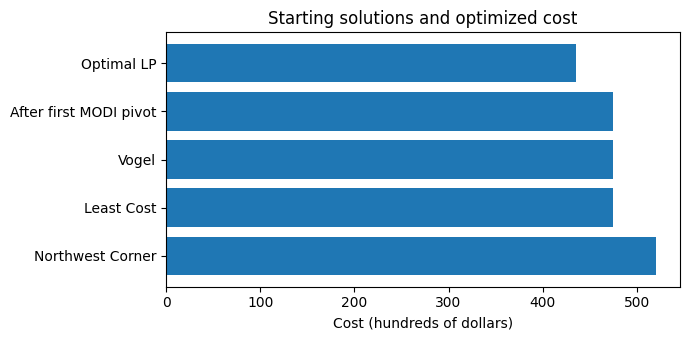

In [38]:
opt,optcost,_=transportation_lp(sc,ss,dd)
comparison=pd.DataFrame({'Method':['Northwest Corner','Least Cost','Vogel','After first MODI pivot','Optimal LP'], 'Cost (hundreds of $)':[np.sum(sc*nw),np.sum(sc*lc),np.sum(sc*vam),np.sum(sc*pivot),optcost]})
display(comparison);display(pd.DataFrame(opt,index=['S1','S2','S3'],columns=['M1','M2','M3','M4']))
assert np.allclose(opt.sum(axis=1),ss) and np.allclose(opt.sum(axis=0),dd)
fig,ax=plt.subplots(figsize=(7,3.5));ax.barh(comparison['Method'],comparison['Cost (hundreds of $)']);ax.set_xlabel('Cost (hundreds of dollars)');ax.set_title('Starting solutions and optimized cost');plt.tight_layout();plt.show()

## 4. Assignment problem and the Hungarian method

**Problem.** Three children, John, Karen, and Terri, submit bids to mow the lawn, paint a door, and wash cars. Each child receives one distinct task and each task must be done exactly once. The objective is to minimize total payment.

| Child | Mow | Paint | Wash |
|---|---:|---:|---:|
| John | 15 | 10 | 9 |
| Karen | 9 | 15 | 10 |
| Terri | 10 | 12 | 8 |

Let $x_{ij}\in\{0,1\}$ indicate whether child $i$ is assigned chore $j$.

$$
\min z=15x_{11}+10x_{12}+9x_{13}+9x_{21}+15x_{22}+10x_{23}+10x_{31}+12x_{32}+8x_{33}.
$$

$$

\begin{aligned}
x_{11}+x_{12}+x_{13}&=1 & x_{11}+x_{21}+x_{31}&=1\\
x_{21}+x_{22}+x_{23}&=1 & x_{12}+x_{22}+x_{32}&=1\\
x_{31}+x_{32}+x_{33}&=1 & x_{13}+x_{23}+x_{33}&=1.
\end{aligned}

$$

### Hungarian algorithm, with arithmetic

1. Subtract each row's minimum. Here $(9,9,8)$, giving

$$

\begin{bmatrix}6&1&0\\0&6&1\\2&4&0\end{bmatrix}.
$$

2. Subtract each column's minimum $(0,1,0)$, giving

$$

\begin{bmatrix}6&0&0\\0&5&1\\2&3&0\end{bmatrix}.
$$

3. Select independent zeros: John–Paint, Karen–Mow, Terri–Wash. The total is $10+9+8=\$27$.

If independent zeros cannot cover all rows, the complete Hungarian procedure covers zeros with the minimum number of lines, updates uncovered entries, and repeats. `scipy.optimize.linear_sum_assignment` performs the complete assignment algorithm.

### Hungarian method: why each operation works

For a square cost matrix $C$, subtracting the same constant from all entries of one row or column changes **every complete assignment** by that constant, so the identity of the minimum-cost assignment does not change. This justifies row and column reductions.

**Complete procedure:**

1. Subtract each row minimum; then subtract each column minimum.
2. Find the maximum number of **independent zeros** (at most one zero per row and column). If there are $n$ independent zeros, they define an optimal assignment.
3. Otherwise, cover all zero entries with the **minimum number of horizontal/vertical lines**. This number is smaller than $n$.
4. Find the smallest **uncovered** value $\delta$. Subtract $\delta$ from uncovered cells, add $\delta$ at intersections of two lines, and leave singly covered cells unchanged.
5. Return to Step 2 until $n$ independent zeros exist. Read each selected position back from the **original cost matrix** to compute the total cost.

The following four-person example prints reductions, minimum zero-cover lines, uncovered minimums, matrix adjustments, and the final original-cost assignment. A small exhaustive search is used only to **explain the zero-cover operations** in this teaching example; SciPy independently verifies the assignment.

In [39]:
ac=np.array([[15,10,9],[9,15,10],[10,12,8]])
rows_min=ac.min(axis=1);r=ac-rows_min[:,None];cols_min=r.min(axis=0);red=r-cols_min
print('Row minima:',rows_min);display(pd.DataFrame(r));print('Column minima:',cols_min);display(pd.DataFrame(red));ii,jj=linear_sum_assignment(ac)
assignment=pd.DataFrame({'Person':np.array(['John','Karen','Terri'])[ii], 'Task':np.array(['Mow','Paint','Wash'])[jj], 'Cost ($)':ac[ii,jj]})
display(assignment);print('Total cost:',ac[ii,jj].sum());assert ac[ii,jj].sum()==27

Row minima: [9 9 8]


,0,1,2
0,6,1,0
1,0,6,1
2,2,4,0


Column minima: [0 1 0]


,0,1,2
0,6,0,0
1,0,5,1
2,2,3,0


,Person,Task,Cost ($)
0,John,Paint,10
1,Karen,Mow,9
2,Terri,Wash,8


Total cost: 27


### A four-person case requiring further Hungarian adjustments

**Problem.** Four children must be assigned four chores with the bid matrix below. Row and column reductions alone may not produce enough independent zeros, requiring the covering/adjustment step. Use the full assignment solver to validate the minimum cost.

In [40]:
four=np.array([[1,4,6,3],[9,7,10,9],[4,5,11,7],[8,7,8,5]])
fr=four-four.min(axis=1,keepdims=True);fc=fr-fr.min(axis=0,keepdims=True)
print('Original:');display(pd.DataFrame(four));print('After row and column reductions:');display(pd.DataFrame(fc))
ri,ci=linear_sum_assignment(four);display(pd.DataFrame({'Child':ri+1,'Chore':ci+1,'Cost':four[ri,ci]}));print('Optimal total payment:',four[ri,ci].sum())

Original:


,0,1,2,3
0,1,4,6,3
1,9,7,10,9
2,4,5,11,7
3,8,7,8,5


After row and column reductions:


,0,1,2,3
0,0,3,2,2
1,2,0,0,2
2,0,1,4,3
3,3,2,0,0


,Child,Chore,Cost
0,1,1,1
1,2,3,10
2,3,2,5
3,4,4,5


Optimal total payment: 21


In [41]:
from itertools import combinations

def zero_matching(a):
    n=a.shape[0];best=[]
    def walk(r,used,selected):
        nonlocal best
        if len(selected)>len(best):best=selected.copy()
        if r==n:return
        walk(r+1,used,selected)
        for j in range(n):
            if abs(a[r,j])<1e-9 and j not in used:
                walk(r+1,used|{j},selected+[(r,j)])
    walk(0,set(),[]);return best

def minimum_zero_cover(a):
    n=a.shape[0];zeros={(i,j) for i in range(n) for j in range(n) if abs(a[i,j])<1e-9}
    for k in range(n+1):
        for nr in range(k+1):
            nc=k-nr
            for rows in combinations(range(n),nr):
                for cols in combinations(range(n),nc):
                    if all(i in rows or j in cols for i,j in zeros):return set(rows),set(cols)
    raise RuntimeError('Zero cover not found')

def hungarian_explained(cost):
    original=np.asarray(cost,float); a=original.copy();n=len(a)
    rowmins=a.min(axis=1);a-=rowmins[:,None]
    print('Original cost matrix:');display(pd.DataFrame(original))
    print('Row minima:',rowmins,'-> row-reduced matrix:');display(pd.DataFrame(a))
    colmins=a.min(axis=0);a-=colmins
    print('Column minima:',colmins,'-> column-reduced matrix:');display(pd.DataFrame(a))
    for k in range(1,25):
        matching=zero_matching(a)
        print(f'Iteration {k}: independent zeros ({len(matching)}/{n}) =',[(i+1,j+1) for i,j in matching])
        if len(matching)==n:
            print('STOP: complete independent-zero assignment is optimal.')
            print('Original assigned costs:',[original[i,j] for i,j in matching], 'total=',sum(original[i,j] for i,j in matching))
            return matching,a
        rows,cols=minimum_zero_cover(a)
        uncovered=[a[i,j] for i in range(n) for j in range(n) if i not in rows and j not in cols]
        delta=min(uncovered)
        print('Minimum zero cover: rows',[i+1 for i in sorted(rows)],'columns',[j+1 for j in sorted(cols)])
        print('Smallest uncovered entry:',delta)
        for i in range(n):
            for j in range(n):
                if i not in rows and j not in cols:a[i,j]-=delta
                elif i in rows and j in cols:a[i,j]+=delta
        print('Updated matrix:');display(pd.DataFrame(a))
    raise RuntimeError('No convergence')

hungarian_match,hungarian_reduced=hungarian_explained(four)
hr,hc=linear_sum_assignment(four)
assert abs(sum(four[i,j] for i,j in hungarian_match)-four[hr,hc].sum())<1e-8
print('SciPy independent verification:',list(zip(hr+1,hc+1)), 'cost =',four[hr,hc].sum())

Original cost matrix:


,0,1,2,3
0,1.0,4.0,6.0,3.0
1,9.0,7.0,10.0,9.0
2,4.0,5.0,11.0,7.0
3,8.0,7.0,8.0,5.0


Row minima: [1. 7. 4. 5.] -> row-reduced matrix:


,0,1,2,3
0,0.0,3.0,5.0,2.0
1,2.0,0.0,3.0,2.0
2,0.0,1.0,7.0,3.0
3,3.0,2.0,3.0,0.0


Column minima: [0. 0. 3. 0.] -> column-reduced matrix:


,0,1,2,3
0,0.0,3.0,2.0,2.0
1,2.0,0.0,0.0,2.0
2,0.0,1.0,4.0,3.0
3,3.0,2.0,0.0,0.0


Iteration 1: independent zeros (3/4) = [(2, 2), (3, 1), (4, 3)]
Minimum zero cover: rows [2, 4] columns [1]
Smallest uncovered entry: 1.0
Updated matrix:


,0,1,2,3
0,0.0,2.0,1.0,1.0
1,3.0,0.0,0.0,2.0
2,0.0,0.0,3.0,2.0
3,4.0,2.0,0.0,0.0


Iteration 2: independent zeros (4/4) = [(1, 1), (2, 3), (3, 2), (4, 4)]
STOP: complete independent-zero assignment is optimal.
Original assigned costs: [np.float64(1.0), np.float64(10.0), np.float64(5.0), np.float64(5.0)] total= 21.0
SciPy independent verification: [(np.int64(1), np.int64(1)), (np.int64(2), np.int64(3)), (np.int64(3), np.int64(2)), (np.int64(4), np.int64(4))] cost = 21


## 5. Transshipment through intermediate facilities

**Problem.** Two manufacturing plants supply 1,000 and 1,200 units. Three dealers need 800, 900, and 500 units. Product may travel through intermediate transfer centers and dealer facilities rather than traveling directly. Such routing may reduce cost.

Let $x_{ij}$ be the quantity shipped along each permitted directed arc $(i,j)$, with cost $c_{ij}$ per unit. Let $b_i$ be net supply ($b_i>0$ at a plant, $b_i<0$ at a dealer, and $b_i=0$ at a pure transit center). The transshipment model is

$$
\min z=\sum_{(i,j)\in A}c_{ij}x_{ij}
$$

$$
\sum_{j:(i,j)\in A}x_{ij}-\sum_{j:(j,i)\in A}x_{ji}=b_i,\qquad i\in N,
$$

$$
x_{ij}\ge0.
$$

To show every actual numerical equation without relying on a partially readable network image, use the following **illustrative routing costs** for the same 2-plant/2-transit/3-dealer structure. These costs are separately constructed, not the printed numerical network costs in Figure 5.7.

| Arc | Cost ($/unit) |
|---|---:|
| P1→T1 | 3 |
| P1→T2 | 6 |
| P2→T1 | 5 |
| P2→T2 | 2 |
| T1→D1 | 2 |
| T1→D2 | 5 |
| T2→D2 | 2 |
| T2→D3 | 6 |
| D2→D3 | 1 |

The explicit balance equations (outflow minus inflow equals supply) are:

$$

\begin{aligned}
x_{P1,T1}+x_{P1,T2}&=1000\\
x_{P2,T1}+x_{P2,T2}&=1200\\
x_{T1,D1}+x_{T1,D2}-x_{P1,T1}-x_{P2,T1}&=0\\
x_{T2,D2}+x_{T2,D3}-x_{P1,T2}-x_{P2,T2}&=0\\
-x_{T1,D1}&=-800\\
x_{D2,D3}-x_{T1,D2}-x_{T2,D2}&=-900\\
-x_{T2,D3}-x_{D2,D3}&=-500.
\end{aligned}

$$

The total cost is the sum of each of the nine listed arc flows multiplied by its cost.

### Transshipment: how the model works

Each node obeys a conservation equation: **outgoing flow minus incoming flow equals net supply**. For example, if plant P1 produces 1,000 units, its outgoing shipments sum to 1,000. At transfer center T1, incoming shipments from both plants must equal shipments sent to downstream dealers. A dealer may receive product and, if transshipment through dealers is permitted, forward some of it. Only its **net incoming** quantity must meet its demand.

The optimization algorithm is a **minimum-cost network-flow** problem: it chooses all allowed arc flows together to minimize the sum of (units shipped × unit cost). Solving each route independently is generally wrong because arcs compete for the same supplies and demands. Below, the exact node equations are solved simultaneously using linear programming. The printed flow audit verifies conservation at every node and decomposes transportation cost by route.

In [42]:
nodes=['P1','P2','T1','T2','D1','D2','D3'];edges=[('P1','T1',3),('P1','T2',6),('P2','T1',5),('P2','T2',2),('T1','D1',2),('T1','D2',5),('T2','D2',2),('T2','D3',6),('D2','D3',1)]
net=np.array([1000,1200,0,0,-800,-900,-500]);inc=np.zeros((len(nodes),len(edges)))
for k,(a,b,c) in enumerate(edges):inc[nodes.index(a),k]=1;inc[nodes.index(b),k]=-1
rr=linprog(np.array([e[2] for e in edges]),A_eq=inc,b_eq=net,bounds=(0,None),method='highs');assert rr.success
flows=pd.DataFrame({'Arc':[a+' → '+b for a,b,_ in edges],'Unit cost':[c for _,_,c in edges],'Units':rr.x,'Route cost':rr.x*np.array([c for _,_,c in edges])})
display(flows);print('Minimum network cost:',rr.fun)
print('Flow-balance residual maximum:',np.max(np.abs(inc@rr.x-net)))
assert np.allclose(inc@rr.x,net)

,Arc,Unit cost,Units,Route cost
0,P1 → T1,3,1000.0,3000.0
1,P1 → T2,6,0.0,0.0
2,P2 → T1,5,0.0,0.0
3,P2 → T2,2,1200.0,2400.0
4,T1 → D1,2,800.0,1600.0
5,T1 → D2,5,200.0,1000.0
6,T2 → D2,2,1200.0,2400.0
7,T2 → D3,6,0.0,0.0
8,D2 → D3,1,500.0,500.0


Minimum network cost: 10900.0
Flow-balance residual maximum: 0.0


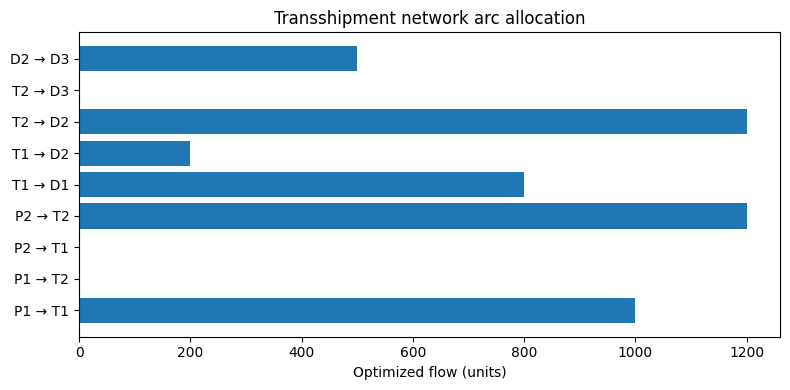

In [43]:
fig,ax=plt.subplots(figsize=(8,4));ax.barh(flows['Arc'],flows['Units']);ax.set_xlabel('Optimized flow (units)');ax.set_title('Transshipment network arc allocation');plt.tight_layout();plt.show()

In [44]:
print('Transshipment node conservation audit:')
flow_map={(a,b):float(v) for a,b,v in zip(flows['From'],flows['To'],flows['Units'])} if {'From','To','Units'}.issubset(flows.columns) else None
if flow_map is None:
    print('Arc flow results:');display(flows)
else:
    for node in nodes:
        out=sum(q for (i,j),q in flow_map.items() if i==node)
        inc=sum(q for (i,j),q in flow_map.items() if j==node)
        print(f'{node}: outflow {out:.1f} - inflow {inc:.1f} = {out-inc:.1f}')

Transshipment node conservation audit:
Arc flow results:


,Arc,Unit cost,Units,Route cost
0,P1 → T1,3,1000.0,3000.0
1,P1 → T2,6,0.0,0.0
2,P2 → T1,5,0.0,0.0
3,P2 → T2,2,1200.0,2400.0
4,T1 → D1,2,800.0,1600.0
5,T1 → D2,5,200.0,1000.0
6,T2 → D2,2,1200.0,2400.0
7,T2 → D3,6,0.0,0.0
8,D2 → D3,1,500.0,500.0


**Interpretation.** The plant balances show all 2,200 units leave production. Transit-center inflows equal outflows. Dealers receive their required quantities, and Dealer 2 may forward material to Dealer 3 if cheaper than direct transit delivery. A transshipment arc should never be interpreted as a physical route unless the actual network permits it.

### Buffer formulation

To convert a network with intermediate nodes into an ordinary transportation tableau, a buffer of $B=2{,}200$ units can be assigned to each transshipment node. Its model supply and demand become original supply or demand plus $B$; allowed self-arcs have zero cost. This transformation is particularly useful when solving through a transportation-tableau interface. The direct network-flow LP above avoids artificial buffers and represents exactly the same flow-conservation principle.

## 6. Validation and operating decisions

For each model verify: (1) solver success; (2) nonnegative allocations; (3) origin supply balances; (4) destination demand balances or correctly interpreted dummy shortages; (5) objective calculation from unit costs and quantities. For the assignment problem, check one task per worker and one worker per task. For transshipment, verify every node's flow conservation.

Operational conclusions should be restricted to the modeled costs, capacities, and routes. The production–inventory model assumes known future demand, the assignment model assumes one-to-one matching, and the transportation LP does not capture congestion or stochastic travel times. These issues require extra constraints or simulation.

### Comparison of transportation starting solutions and the certified optimum

Northwest Corner ignores freight costs, Least Cost uses the cheapest currently available route, and VAM uses differences between low-cost alternatives to prioritize allocations. Their allocations are feasible but may not be optimal. MODI tests the nonbasic reduced costs and improves the allocation until no negative reduced cost remains. The next output compares all methods in **hundreds of dollars** and confirms the optimal cost using an independent linear-programming solver.

In [45]:
method_costs = pd.DataFrame({
    'Method': ['Northwest Corner', 'Least Cost', 'Vogel Approximation', 'MODI', 'LP Solver'],
    'Cost (hundreds of dollars)': [np.sum(nw_x*sc), np.sum(lc_x*sc), np.sum(vam_x*sc), np.sum(modi_x*sc), optcost]
})
display(method_costs)
assert np.isclose(np.sum(modi_x*sc), optcost)
print('MODI required',len(modi_history)-1,'improving pivots and ended with an optimality certificate.')

,Method,Cost (hundreds of dollars)
0,Northwest Corner,520.0
1,Least Cost,475.0
2,Vogel Approximation,475.0
3,MODI,435.0
4,LP Solver,435.0


MODI required 2 improving pivots and ended with an optimality certificate.


In [46]:
assert np.allclose(mg_x.sum(axis=1),mg_s) and np.allclose(mg_x.sum(axis=0),mg_d)
assert np.allclose(production.sum(axis=1),bs) and np.allclose(production.sum(axis=0),bd)
assert np.allclose(opt.sum(axis=1),ss) and np.allclose(opt.sum(axis=0),dd)
assert abs(float(ac[ii,jj].sum())-27)<1e-9
assert np.allclose(inc@rr.x,net)
print('All major model validation checks passed.')

All major model validation checks passed.


## Reference

Taha, H. A. (2007). *Operations Research: An Introduction* (8th ed.). Pearson Prentice Hall, Chapter 5, pp. 193–234. Named examples: MG Auto (§5.1), Boralis (§5.2), SunRay (§5.3), Klyne assignment (§5.4), and the transshipment network structure (§5.5). The transshipment cost scenario in this notebook is illustrative.